In [3]:
import numpy as np 
import matplotlib.pyplot as plt 
rng = np.random.default_rng(42)

In [26]:
Re = rng.uniform(60, 160, size= 100)


In [27]:
St_true = -3.3265/Re + 0.1816 + 1.6e-04 * Re

In [28]:
noise = rng.normal(0, St_true * 0.01, size=len(Re))
St = St_true + noise 

In [29]:
Re_line = np.linspace(50, 180,200)
St_line = -3.3265/Re_line + 0.1816 + 1.6e-04 * Re_line

In [30]:
def williamson(Re):
    return -3.3265/Re + 0.1816 + 1.6e-04 * Re

<function matplotlib.pyplot.show(close=None, block=None)>

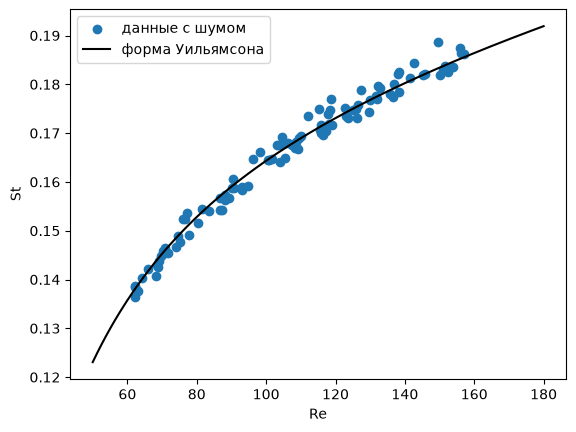

In [31]:
plt.scatter(Re, St, label="данные с шумом ")
plt.plot(Re_line, St_line, color="k", label="форма Уильямсона")
plt.xlabel("Re")
plt.ylabel("St")
plt.legend()
plt.show

In [32]:
path = "/home/rvstxm/cylinder-ml/cases/cylinder_Re100/postProcessing/forceCoeffsIncompressible/0/forceCoeffs.dat"

In [33]:
data = np.loadtxt(path, comments="#")
print(data.shape)

(14912, 6)


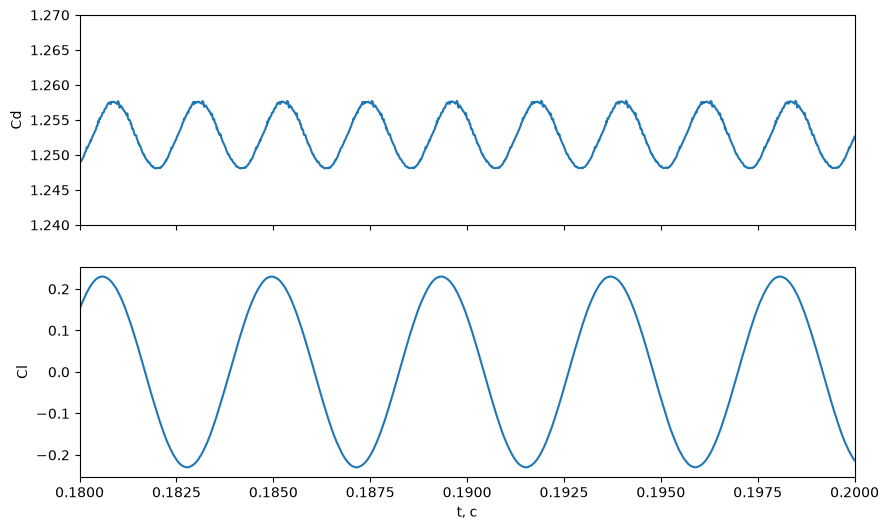

In [34]:
t = data[:, 0]
Cd = data[:, 2]
Cl = data[:, 3]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,6), sharex=True)
ax1.plot(t, Cd)
ax1.set_ylabel("Cd")
ax1.set_ylim(1.0, 1.5)
ax2.set_xlim(0.18, 0.20)
ax1.set_ylim(1.24, 1.27)
ax2.plot(t, Cl)
ax2.set_ylabel("Cl")
ax2.set_xlabel("t, c")
plt.show()

In [35]:
from sklearn.model_selection import train_test_split

X = Re.reshape(-1,1)
y = St

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25 , random_state=42  
)
print(len(X_train), len(X_test))

75 25


In [36]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"MAE = {mae:.5f}   RMSE = {rmse:.5f}   R2 = {r2:.4f}")

MAE = 0.00253   RMSE = 0.00315   R2 = 0.9576


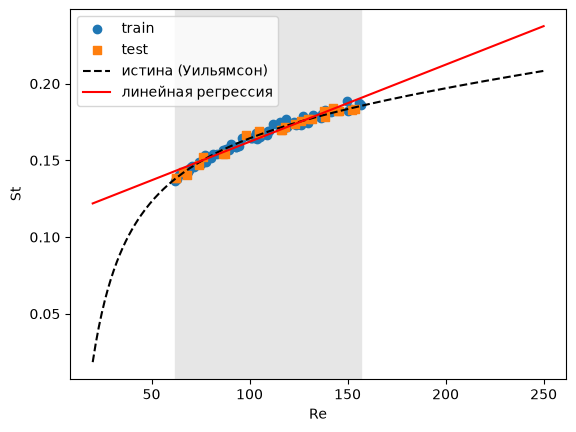

In [38]:
Re_plot = np.linspace(20, 250, 300).reshape(-1, 1)

plt.scatter(X_train, y_train, label="train")
plt.scatter(X_test, y_test, label="test", marker="s")
plt.plot(Re_plot, williamson(Re_plot), "k--", label="истина (Уильямсон)")
plt.plot(Re_plot, model.predict(Re_plot), "r", label="линейная регрессия")
plt.axvspan(X.min(),X.max(), color="0.9", zorder = 0)
plt.xlabel("Re"); plt.ylabel("St"); plt.legend()
plt.show()

In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def poly_model(degree):
    return make_pipeline(
        PolynomialFeatures(degree),
        StandardScaler(),
        LinearRegression(),
    )

степень  1: RMSE train=0.00267, RMSE test= 0.00315
степень  2: RMSE train=0.00170, RMSE test= 0.00186
степень  3: RMSE train=0.00164, RMSE test= 0.00184
степень  5: RMSE train=0.00162, RMSE test= 0.00193
степень 10: RMSE train=0.00161, RMSE test= 0.00197
степень 15: RMSE train=0.00159, RMSE test= 0.00190


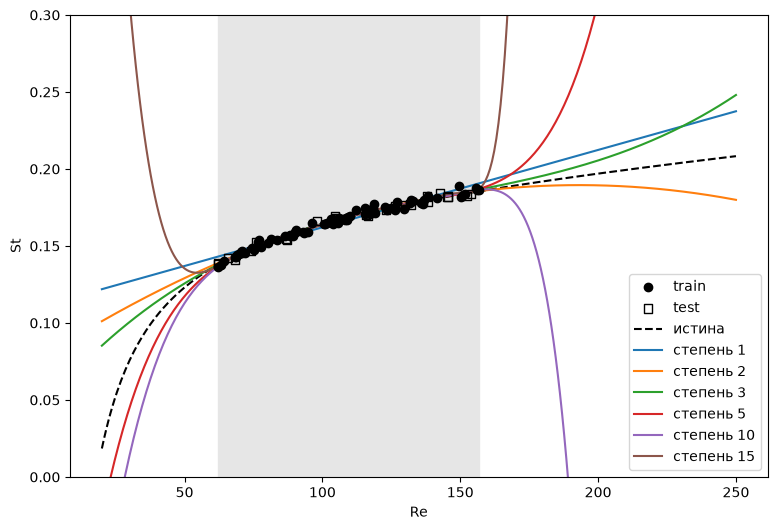

In [40]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def poly_model(degree):
    return make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())

degrees = [1, 2, 3, 5, 10, 15]

plt.figure(figsize=(9, 6))
plt.scatter(X_train, y_train, color="k", label="train", zorder = 3)
plt.scatter(X_test, y_test, color="k", marker="s", facecolors="none", label="test", zorder = 3)
plt.plot(Re_plot, williamson(Re_plot), "k--", label="истина")

for d in degrees:
    model = poly_model(d)
    model.fit(X_train, y_train)
    rmse_train = np.sqrt(mean_squared_error(y_train,model.predict(X_train)))
    rmse_test  = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    print(f"степень {d:2d}: RMSE train={rmse_train:.5f}, RMSE test= {rmse_test:.5f}")
    plt.plot(Re_plot, model.predict(Re_plot), label=f"степень {d}")

plt.axvspan(X.min(), X.max(), color = "0.9", zorder = 0)
plt.ylim(0, 0.3)
plt.xlabel("Re"); plt.ylabel("St"); plt.legend()
plt.show()

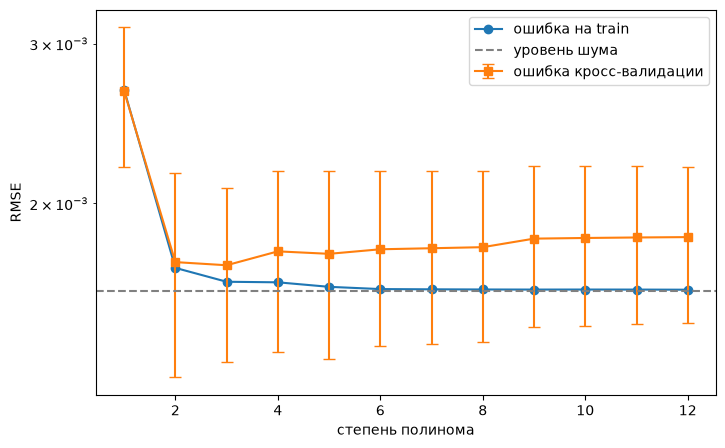

3 0.0018374166103249103


In [41]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)
degrees = np.arange(1,13)

cv_mean, cv_std, train_rmse = [], [], []

for d in degrees:
    scores = cross_val_score(
        poly_model(d), X_train, y_train,
        cv=cv, scoring="neg_root_mean_squared_error",
    )

    rmse = -scores 
    cv_mean.append(rmse.mean())
    cv_std.append(rmse.std())

    m = poly_model(d).fit(X_train, y_train)
    train_rmse.append(np.sqrt(mean_squared_error(y_train, m.predict(X_train))))

cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)

plt.figure(figsize=(8,5))
plt.plot(degrees, train_rmse, "o-", label="ошибка на train")
plt.errorbar(degrees, cv_mean, yerr=cv_std, fmt="s-", capsize=4, label="ошибка кросс-валидации")
plt.axhline(0.0016, color="gray", ls="--", label="уровень шума")
plt.yscale("log")
plt.xlabel("степень полинома"); plt.ylabel("RMSE")
plt.legend(); plt.show()

best_d = degrees[np.argmin(cv_mean)]
final = poly_model(best_d).fit(X_train, y_train)
print(best_d, np.sqrt(mean_squared_error(y_test, final.predict(X_test))))